# Basic Chatbot

A basic chatbot with langgraph(Graph api)

In [124]:
from typing import Annotated
from typing_extensions import TypedDict

from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages


In [125]:
class State(TypedDict):
    messages:Annotated[list,add_messages]


In [126]:
import os
from langchain_nvidia_ai_endpoints import ChatNVIDIA
from IPython.display import display, Markdown

model = ChatNVIDIA(
  base_url="https://integrate.api.nvidia.com/v1",
  model="nvidia/nemotron-3.5-super-vl-120b-a12b",
  api_key=os.environ["NVIDIA_API_KEY"],
  temperature=1,
  top_p=0.95,
  max_completion_tokens=16384,
  seed=42,
)

try:
  response= model.invoke("My name is rudra , So tell me what is my name")
  print(display(response.content))
except Exception as e:
    print("Error type:", type(e).__name__)
    print("Error details:", str(e))

'Your name is **Rudra**.'

None


In [127]:
## Node functionality
def chatbot(state:State):
    return {"messages":[model.invoke(state["messages"])]}
    

In [128]:
graph_builder = StateGraph(State)

##Adding node
#node+defination
graph_builder.add_node("llmchatbot",chatbot)


##Adding edges
graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge("llmchatbot",END)

##compiles the graph
graph = graph_builder.compile()


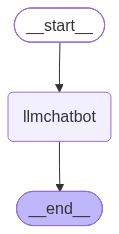

In [129]:
from langchain_core.runnables.graph_mermaid import draw_mermaid_png
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [130]:
response  = graph.invoke({"messages":"Hi"})

response["messages"][-1].content

'Hello! How can I help you today?'

In [131]:
## streaming of the graph
for event in graph.stream({"messages":"Hi How are you?"}):
    for value in event.values():
        print(value["messages"][-1].content)

Hi there! I'm doing well, thanks for asking. How are you doing?

Is there anything I can help you with today?


## Chatbot with the help of Tool


In [132]:
import os
from dotenv import load_dotenv
load_dotenv()
os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")

api_key = os.getenv("TAVILY_API_KEY")
if not api_key:
    raise ValueError("TAVILY_API_KEY not found in .env file")

print("API key loaded successfully!")

API key loaded successfully!


In [133]:
## tool calling llm -> [llm + tools]
from langchain_tavily import TavilySearch

tavily_tool = TavilySearch(max_results=2)
tavily_tool.invoke("What is langgraph")


{'query': 'What is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.geeksforgeeks.org/machine-learning/what-is-langgraph',
   'title': 'What is LangGraph - GeeksforGeeks',
   'content': 'LangGraph is an open-source framework from LangChain designed to build and manage AI agent workflows using graph-based structures. It allows developers to define workflows as nodes and edges, making complex agent interactions more structured, scalable and easier to control. [...] langgraph: Framework for building graph-based AI workflows.\n langchain: Popular toolkit for LLM-powered AI applications.\n google-generativeai: Google’s API for Generative AI (Gemini models).\n\n Python  ````\n! pip install langgraph langchain google - generativeai\n```` \n\n### Step 2: Setup Gemini API [...] ## Building a Simple Chatbot with LangGraph\n\nLangGraph makes it easy to build structured, stateful applications like chatbots. In this example we’ll learn how 

In [134]:
## Custom function

def multiply(a: int, b: int) -> int:
    """Multiply a and b.
    
    Args:
        a (int): first int
        b (int): second int

    Returns:
        int: output int
    """
    return a * b


In [135]:
tools=[tavily_tool,multiply]

In [136]:
llm_with_tool = model.bind_tools(tools)
llm_with_tool

_ChatModelBinding(bound=ChatNVIDIA(metadata={'lc_versions': {'langchain-core': '1.6.10', 'langchain': '1.4.5', 'langchain-nvidia-ai-endpoints': '1.5.0'}}, profile={'name': 'Nemotron 3.5 Super VL', 'text_inputs': True, 'image_inputs': True, 'text_outputs': True, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True}, base_url='https://integrate.api.nvidia.com/v1', model='nvidia/nemotron-3.5-super-vl-120b-a12b', temperature=1.0, max_tokens=16384, top_p=0.95, seed=42, default_headers={}, model_kwargs={}), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, and trusted results. Useful for when you need to answer questions about current events. It not only retrieves URLs and snippets, but offers advanced search depths, domain management, time range filters, and image search, this tool delivers real-time, accurate, and citation-backed results.Input should be a search query.', '

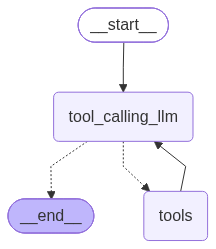

================================ Human Message =================================

Please tell me the latest ai news
================================== Ai Message ==================================
Tool Calls:
  tavily_search (call-8086207c-cb6e-44fa-8521-0bae01b44466)
 Call ID: call-8086207c-cb6e-44fa-8521-0bae01b44466
  Args:
    query: latest AI news
    topic: news
    search_depth: advanced
    time_range: week
    include_images: False
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://fedscoop.com/dhs-ai-policy-updates", "title": "What’s new in Homeland Security’s updated AI policy | FedScoop", "content": "Some sources, however, questioned whether ICE would even need to follow its own rules, given the latest AI policy includes a provision allowing the agency’s chief AI officer to waive any requirement outlined in th

In [138]:
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode,tools_condition


##Node defination
def tool_calling_llm(state: State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}




##graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))


##edges
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    #If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    #If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
    )
builder.add_edge("tools","tool_calling_llm")

##compile the graph
graph = builder.compile()



try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

response = graph.invoke({"messages":"Please tell me the latest ai news"})


for m in response["messages"]:
    m.pretty_print()

In [139]:
response = graph.invoke({"messages":"Give me recent ai news and then multiply 5 by 2"})


for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Give me recent ai news and then multiply 5 by 2
================================== Ai Message ==================================
Tool Calls:
  tavily_search (call-5c7d31c0-d276-4c31-8c0e-d07cbdf11830)
 Call ID: call-5c7d31c0-d276-4c31-8c0e-d07cbdf11830
  Args:
    query: recent AI news
    search_depth: fast
    topic: general
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.umu.com/ask/t11122301573854365892", "title": "ai recent developments june 2025 news", "score": 0.9976495, "content": "Recent advancements in AI by June 2025 highlight significant breakthroughs in areas such as autonomous systems, deep learning frameworks, and ethical AI usage. Companies are focusing on using these advancements to enhance productivity and streamline

# Adding memory in agentic graph


In [ ]:
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode,tools_condition
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

##Node defination
def tool_calling_llm(state: State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}




##graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))


##edges
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    #If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    #If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
    )
builder.add_edge("tools","tool_calling_llm")

##compile the graph
graph = builder.compile(checkpointer=memory)



try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

response = graph.invoke({"messages":"Please tell me the latest ai news"})


for m in response["messages"]:
    m.pretty_print()